# 01 - Prototype : jeux coopératifs

Groupe 4. Les fonctions sont dans `src/jeux.py`. Ce notebook vérifie qu'elles retrouvent les résultats du cours.

In [1]:
import sys
sys.path.insert(0, '../src')
import numpy as np
import matplotlib.pyplot as plt
from jeux import (shapley_exact, shapley_mc, coeur_lp, shapley_shubik,
                  dans_coeur, jeu_depuis_dict)

## 1. Jeu du cours

$v(\{1,2\}) = v(\{1,3\}) = 60$, $v(\{2,3\}) = 0$, $v(N) = 90$. Joueurs 1, 2, 3 = indices 0, 1, 2.

In [3]:
cours = jeu_depuis_dict({
    frozenset({0, 1}): 60, frozenset({0, 2}): 60,
    frozenset({1, 2}): 0,  frozenset({0, 1, 2}): 90,
})
print('Shapley exact :', shapley_exact(3, cours))   # attendu (50, 20, 20)

Shapley exact : [50. 20. 20.]


## 2. Cœur

(0, 45, 45) doit être hors du cœur, et le point trouvé par `linprog` dedans.

In [4]:
print('(0, 45, 45) dans le coeur ?', dans_coeur(3, cours, [0, 45, 45]))
x = coeur_lp(3, cours)
print('Point du coeur (linprog) :', x, dans_coeur(3, cours, x))

(0, 45, 45) dans le coeur ? False
Point du coeur (linprog) : [90. -0. -0.] True


## 3. Cœur vide : majorité simple à 3 joueurs

In [5]:
majorite = lambda m: 1.0 if bin(m).count('1') >= 2 else 0.0
print('Coeur :', coeur_lp(3, majorite))   # attendu None

Coeur : None


## 4. Vote pondéré [51 ; 40, 30, 20, 10]

In [6]:
print('Shapley-Shubik :', shapley_shubik(51, [40, 30, 20, 10]))   # attendu (5/12, 1/4, 1/4, 1/12)

Shapley-Shubik : [0.41666667 0.25       0.25       0.08333333]


## 5. Monte-Carlo contre exact

10 [57. 15. 18.] [12.33  4.74  8.69]
100 [52.8 20.4 16.8] [3.6  2.24 2.09]
1000 [52.44 19.2  18.36] [1.17 0.7  0.69]
10000 [50.04 19.92 20.04] [0.37 0.22 0.22]


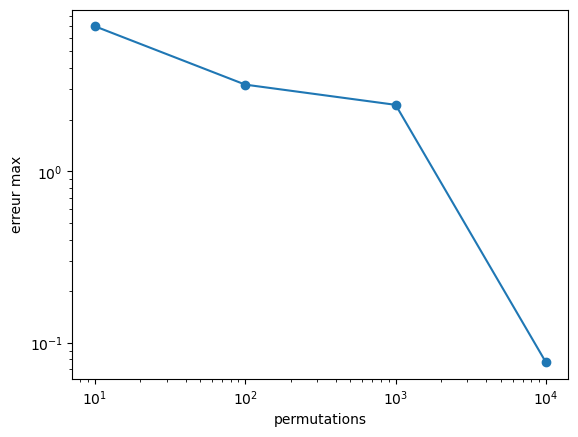

In [7]:
exact = shapley_exact(3, cours)
nb = [10, 100, 1000, 10000]
erreurs = []
for n_perm in nb:
    phi, se = shapley_mc(3, cours, n_perm, seed=0)
    erreurs.append(np.abs(phi - exact).max())
    print(n_perm, phi.round(2), se.round(2))
plt.loglog(nb, erreurs, 'o-')
plt.xlabel('permutations'); plt.ylabel('erreur max'); plt.show()